In [1]:
import pandas as pd
import numpy as np
import pickle
import os
import bambi as bmb
import matplotlib.pylab as plt
from s0_fun_IPMs import IPM_listk, kernel_setting, IPM_listk_glmmcmc
from s0_fun_IBMs import popu_structure, IBM_1step_glm_mle, IBM_1step_gp, IBM_1step_glm
from s0_fun_base import XY_sur_compu, XY_grw_f_compu, XY_grw_nf_compu, XY_fec_compu, XY_flow_compu, XY_grw_compu
import gpflow
from tensorflow_probability import distributions as tfd
f64 = gpflow.utilities.to_default_float
import seaborn as sns
import matplotlib
from matplotlib.ticker import MaxNLocator

In [2]:
# Loading populations
gp_mle_true_population = pickle.load(open(file = os.getcwd()+f"/true_popu/gp_mle_true_population/gp_mle_true_population.pkl", mode="rb")) 
popu_whole = pickle.load(open(file = os.getcwd()+f"/true_popu/popu_whole.pkl", mode="rb")) 

# True models
gp_mle_true_models = pickle.load(open(file = os.getcwd()+f"/true_popu/gp_mle_true_models.pkl", mode="rb"))

# IPM Mesh setting
lower_p = 0
upper_p = 5
m_size_p = 50
mesh_setting = kernel_setting(m_size_p, lower_p, upper_p)
Xp = mesh_setting[0]
step_size = m_size_p // 5
ticks = [i * step_size for i in range(0, 6)]
ticks[-1] = m_size_p - 1

# IPMs for true models
true_p_gp, true_f_gp = IPM_listk(mesh_setting=mesh_setting, models=gp_mle_true_models, grw_setting='sep')
observed_lambda_gp = (np.sum(np.isnan(gp_mle_true_population["size"])) + np.sum(gp_mle_true_population["surv"] == 1)) / np.sum(np.logical_not(np.isnan(gp_mle_true_population["size"])))

# lambdas
true_lambda_gp = np.linalg.eig(true_p_gp+true_f_gp)[0][0]

# eigenvects
true_repro_gp = np.linalg.eig(true_p_gp.T+true_f_gp.T)[1][:,0].real/np.linalg.eig(true_p_gp.T+true_f_gp.T)[1][:,0].real[0]
true_stable_gp = np.linalg.eig(true_p_gp+true_f_gp)[1][:,0].real/np.sum(np.linalg.eig(true_p_gp+true_f_gp)[1][:,0].real)

true_stable_rep_gp = true_stable_gp * np.array(gp_mle_true_models["m_fec"].predict_y(Xp[:, None])[0]).reshape(-1)
true_stable_rep_gp = true_stable_rep_gp/np.sum(true_stable_rep_gp)

# empi_lambda_gp = []
# np.random.seed(123456)
# z0 = popu_structure(gp_mle_true_population)
# for i in range(5000):
#     simu = IBM_1step_gp(zt=z0[0], age=z0[1], models=gp_mle_true_models)
#     empi_lambda_gp.append((np.sum(np.isnan(simu["size"])) + np.sum(simu["surv"] == 1)) / np.sum(np.logical_not(np.isnan(simu["size"]))))
#     del(simu)


# pickle.dump(empi_lambda_gp, open(file = os.getcwd()+f"/true_popu/empi_lambda_gp.pkl", mode="wb"))


empi_lambda_gp = pickle.load(open(file = os.getcwd()+f"/true_popu/empi_lambda_gp.pkl", mode="rb"))

In [3]:
re_ipm = False 

In [4]:
if re_ipm == True:

    #setting
    truedata_style='gp'
    grw_setting='sep'
    model_type = 'glm'

    # Loading GLM MCMCs for glm datasets
    globals()[f'trace_{truedata_style}data'] = {}
    globals()[f'trace_{truedata_style}data']['trace_grw_f'] = pickle.load(open(file = os.getcwd()+f"/true_popu/"+truedata_style+"_mle_true_population/MCMC/"+model_type+"/"+grw_setting+"/trace_grw_f.pkl", mode="rb"))
    globals()[f'trace_{truedata_style}data']['trace_grw_nf'] = pickle.load(open(file = os.getcwd()+f"/true_popu/"+truedata_style+"_mle_true_population/MCMC/"+model_type+"/"+grw_setting+"/trace_grw_nf.pkl", mode="rb"))
    globals()[f'trace_{truedata_style}data']['trace_fec'] = pickle.load(open(file = os.getcwd()+f"/true_popu/"+truedata_style+"_mle_true_population/MCMC/"+model_type+"/"+grw_setting+"/trace_fec.pkl", mode="rb"))
    globals()[f'trace_{truedata_style}data']['trace_flow'] = pickle.load(open(file = os.getcwd()+f"/true_popu/"+truedata_style+"_mle_true_population/MCMC/"+model_type+"/"+grw_setting+"/trace_flow.pkl", mode="rb"))
    globals()[f'trace_{truedata_style}data']['trace_sur'] = pickle.load(open(file = os.getcwd()+f"/true_popu/"+truedata_style+"_mle_true_population/MCMC/"+model_type+"/"+grw_setting+"/trace_sur.pkl", mode="rb"))

    globals()[f'model_{truedata_style}data'] = {}
    df_grw_f = XY_grw_f_compu(globals()[f'{truedata_style}_mle_true_population'])
    globals()[f'model_{truedata_style}data']['m_grw_f'] = bmb.Model("sizeNext ~ size", pd.concat(df_grw_f, axis=1))
    # grw_nf
    df_grw_nf = XY_grw_nf_compu(globals()[f'{truedata_style}_mle_true_population'])
    globals()[f'model_{truedata_style}data']['m_grw_nf'] = bmb.Model("sizeNext ~ size", pd.concat(df_grw_nf, axis=1))
    # sur
    df_sur = XY_sur_compu(globals()[f'{truedata_style}_mle_true_population'])
    globals()[f'model_{truedata_style}data']['m_sur'] = bmb.Model("sur ~ size", pd.concat(df_sur, axis=1), family='bernoulli')
    # fec
    df_fec = XY_fec_compu(globals()[f'{truedata_style}_mle_true_population'])
    globals()[f'model_{truedata_style}data']['m_fec'] = bmb.Model("fec ~ size", pd.concat(df_fec, axis=1), family='bernoulli')
    # flow
    df_flow = XY_flow_compu(globals()[f'{truedata_style}_mle_true_population'])
    globals()[f'model_{truedata_style}data']['m_flow_poi'] = bmb.Model("flow ~ size", pd.concat(df_flow, axis=1), family='poisson')
    # recru
    globals()[f'model_{truedata_style}data']['recruit_p'] = globals()[f'{truedata_style}_mle_true_models']['recruit_p']
    globals()[f'model_{truedata_style}data']['alpha'] = globals()[f'{truedata_style}_mle_true_models']['alpha']
    globals()[f'model_{truedata_style}data']['beta'] = globals()[f'{truedata_style}_mle_true_models']['beta']

    np.random.seed(1234567)
    index = {}; diff_p = {}; diff_f = {}; growth_rate={}; stable = {}; repro={}; stable_rep = {}
    for i in range(5000):
        c_index = np.random.randint(low=0, high=[5000, 5000, 5000, 5000, 5000], size=5)
        c_p, c_f = IPM_listk_glmmcmc(mesh_setting=mesh_setting, models=globals()[f'model_{truedata_style}data'], 
                                    traces=globals()[f'trace_{truedata_style}data'], index=c_index, grw_setting=grw_setting)
        index[i] = c_index
        diff_p[i] = c_p - globals()[f'true_p_{truedata_style}']
        diff_f[i] = c_f - globals()[f'true_f_{truedata_style}']
        eig1 = np.linalg.eig(c_p+c_f)
        eigT = np.linalg.eig(c_p.T+c_f.T) 
        growth_rate[i] = eig1[0][0]
        stable[i] = eig1[1][:,0].real/np.sum(eig1[1][:,0].real)
        repro[i] = eigT[1][:,0].real; del(eig1); del(eigT)
        stable_rep[i] = stable[i] * globals()[f'model_{truedata_style}data']["m_fec"].predict(globals()[f'trace_{truedata_style}data']["trace_fec"], 
                                                                                              data=pd.DataFrame(Xp, columns=['size']), inplace=False).posterior['fec_mean'].values[0][c_index[0], : ]
        stable_rep[i] = stable_rep[i]/np.sum(stable_rep[i])

    pickle.dump(index, open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/index.pkl", mode="wb"))
    pickle.dump(growth_rate, open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/growth_rate.pkl", mode="wb"))
    pickle.dump(stable, open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/stable.pkl", mode="wb"))
    pickle.dump(repro, open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/repro.pkl", mode="wb"))
    pickle.dump(stable_rep, open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/stable_rep.pkl", mode="wb"))
else:
    #setting
    truedata_style='gp'
    grw_setting='sep'
    model_type = 'glm' 

    diff_p = pickle.load(open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/diff_p.pkl", mode="rb"))
    diff_f = pickle.load(open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/diff_f.pkl", mode="rb"))
    growth_rate_glm_sep = pickle.load(open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/growth_rate.pkl", mode="rb"))
    stable_glm_sep = pickle.load(open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/stable.pkl", mode="rb"))
    repro_glm_sep = pickle.load(open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/repro.pkl", mode="rb"))
    stable_rep_glm_sep = pickle.load(open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/stable_rep.pkl", mode="rb"))

In [5]:
if re_ipm == True:
    #setting
    truedata_style='gp'
    grw_setting='sep'
    model_type = 'gp'

    #Loading data
    samples_grw_f = pickle.load(open(file = os.getcwd()+f"/true_popu/"+truedata_style+"_mle_true_population/MCMC/gp/sep/samples_grw_f.pkl", mode="rb"))
    samples_grw_nf = pickle.load(open(file = os.getcwd()+f"/true_popu/"+truedata_style+"_mle_true_population/MCMC/gp/sep/samples_grw_nf.pkl", mode="rb"))
    samples_sur = pickle.load(open(file = os.getcwd()+f"/true_popu/"+truedata_style+"_mle_true_population/MCMC/gp/sep/samples_sur.pkl", mode="rb"))
    samples_flow = pickle.load(open(file = os.getcwd()+f"/true_popu/"+truedata_style+"_mle_true_population/MCMC/gp/sep/samples_flow.pkl", mode="rb"))
    samples_fec = pickle.load(open(file = os.getcwd()+f"/true_popu/"+truedata_style+"_mle_true_population/MCMC/gp/sep/samples_fec.pkl", mode="rb"))

    popu_dataset = globals()[f'{truedata_style}_mle_true_population']

    # Fec
    df_fec = XY_fec_compu(popu_dataset)  
    m_fec_new = gpflow.models.GPMC(data=(df_fec[0], df_fec[1]), 
                                kernel=gpflow.kernels.RBF(), likelihood=gpflow.likelihoods.Bernoulli())

    m_fec_new.kernel.variance.prior = tfd.InverseGamma(f64(0.001),f64(0.001))
    m_fec_new.kernel.lengthscales.prior = tfd.Normal(loc=f64(0.), scale=f64(100.))
    hmc_helper_fec = gpflow.optimizers.SamplingHelper(
        m_fec_new.log_posterior_density, m_fec_new.trainable_parameters
    )


    # Flow poi
    df_flow = XY_flow_compu(popu_dataset)  
    m_flow_poi_new =  gpflow.models.GPMC(data=(df_flow[0], df_flow[1]), 
                                    kernel=gpflow.kernels.RBF(), likelihood=gpflow.likelihoods.Poisson())
    m_flow_poi_new.kernel.lengthscales.prior = tfd.HalfNormal(scale=f64(100.))
    m_flow_poi_new.kernel.variance.prior = tfd.HalfNormal(scale=f64(100.))
    hmc_helper_flow = gpflow.optimizers.SamplingHelper(
        m_flow_poi_new.log_posterior_density, m_flow_poi_new.trainable_parameters
    )



    # Grw_f
    df_grw_f = XY_grw_f_compu(popu_dataset)    
    m_grw_f_new = gpflow.models.GPR(data=(df_grw_f[0], df_grw_f[1]), kernel=gpflow.kernels.RBF())
    m_grw_f_new.kernel.lengthscales.prior = tfd.HalfNormal(scale=f64(100.))
    m_grw_f_new.kernel.variance.prior = tfd.HalfNormal(scale=f64(100.))
    m_grw_f_new.likelihood.variance.prior = tfd.HalfNormal(scale=f64(100.))
    hmc_helper_grw_f = gpflow.optimizers.SamplingHelper(
        m_grw_f_new.log_posterior_density, m_grw_f_new.trainable_parameters
    )



    # Grw_nf
    df_grw_nf = XY_grw_nf_compu(popu_dataset)    
    m_grw_nf_new = gpflow.models.GPR(data=(df_grw_nf[0], df_grw_nf[1]), kernel=gpflow.kernels.RBF())
    # we add priors to the hyperparameters.
    m_grw_nf_new.kernel.lengthscales.prior = tfd.HalfNormal(scale=f64(100.))
    m_grw_nf_new.kernel.variance.prior = tfd.HalfNormal(scale=f64(100.))
    m_grw_nf_new.likelihood.variance.prior = tfd.HalfNormal(scale=f64(100.))
    hmc_helper_grw_nf = gpflow.optimizers.SamplingHelper(
        m_grw_nf_new.log_posterior_density, m_grw_nf_new.trainable_parameters
    )



    # Sur
    df_sur = XY_sur_compu(popu_dataset)  
    m_sur_new = gpflow.models.GPMC(data=(df_sur[0], df_sur[1]), 
                                kernel=gpflow.kernels.RBF(), likelihood=gpflow.likelihoods.Bernoulli())

    m_sur_new.kernel.lengthscales.prior = tfd.HalfNormal(scale=f64(50.))
    m_sur_new.kernel.variance.prior = tfd.HalfNormal(scale=f64(50.))
    hmc_helper_sur = gpflow.optimizers.SamplingHelper(
        m_sur_new.log_posterior_density, m_sur_new.trainable_parameters
    )


    np.random.seed(1234567)
    index = {}; diff_p = {}; diff_f = {}; growth_rate={}; stable = {}; repro={}; stable_rep = {}
    for i in range(5000):
        c_index = np.random.randint(low=0, high=[5000, 5000, 5000, 5000, 5000], size=5)

        for var, var_samples in zip(hmc_helper_sur.current_state, samples_sur):
            var.assign(var_samples[c_index[0]])
        # grw_f
        for var, var_samples in zip(hmc_helper_grw_f.current_state, samples_grw_f):
            var.assign(var_samples[c_index[1]])
        # grw_nf
        for var, var_samples in zip(hmc_helper_grw_nf.current_state, samples_grw_nf):
            var.assign(var_samples[c_index[2]])
        # fec
        for var, var_samples in zip(hmc_helper_fec.current_state, samples_fec):
            var.assign(var_samples[c_index[3]])
        # flow
        for var, var_samples in zip(hmc_helper_flow.current_state, samples_flow):
            var.assign(var_samples[c_index[4]])


        models_now = {
            "m_sur": m_sur_new ,
            "m_grw_f": m_grw_f_new,
            "m_grw_nf": m_grw_nf_new ,
            "m_fec": m_fec_new,
            "m_flow_poi": m_flow_poi_new,
            "alpha": globals()[f'{truedata_style}_mle_true_models']['alpha'],
            "beta": globals()[f'{truedata_style}_mle_true_models']['beta'],
            "recruit_p": globals()[f'{truedata_style}_mle_true_models']['recruit_p']
        }


        c_p, c_f = IPM_listk(mesh_setting=mesh_setting, models=models_now, grw_setting=grw_setting)
        # index[i] = c_index
        diff_p[i] = c_p - globals()[f'true_p_{truedata_style}']
        diff_f[i] = c_f - globals()[f'true_f_{truedata_style}']
        eig1 = np.linalg.eig(c_p+c_f)
        eigT = np.linalg.eig(c_p.T+c_f.T) 
        growth_rate[i] = eig1[0][0]
        stable[i] = eig1[1][:,0].real/np.sum(eig1[1][:,0].real)
        repro[i] = eigT[1][:,0].real; del(eig1); del(eigT)
        stable_rep[i] = stable[i] * np.array(models_now["m_fec"].predict_y(Xp[:, None])[0]).reshape(-1)
        stable_rep[i] = stable_rep[i]/np.sum(stable_rep[i])

    pickle.dump(growth_rate, open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/growth_rate.pkl", mode="wb"))
    pickle.dump(stable, open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/stable.pkl", mode="wb"))
    pickle.dump(repro, open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/repro.pkl", mode="wb"))
    pickle.dump(stable_rep, open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/stable_rep.pkl", mode="wb"))

else:
    #setting
    truedata_style='gp'
    grw_setting='sep'
    model_type = 'gp' 

    growth_rate_gp_sep = pickle.load(open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/growth_rate.pkl", mode="rb"))
    stable_gp_sep = pickle.load(open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/stable.pkl", mode="rb"))
    repro_gp_sep = pickle.load(open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/repro.pkl", mode="rb"))
    stable_rep_gp_sep = pickle.load(open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/stable_rep.pkl", mode="rb"))


In [6]:
if re_ipm == True:
    #setting
    truedata_style='gp'
    grw_setting='sep'
    model_type = 'gpabc'

    abc_index = np.load(open(file = os.getcwd()+f"/ABC_details/{truedata_style+grw_setting}/p_index_9.pkl", mode="rb"))
    abc_weight = np.load(open(file = os.getcwd()+f"/ABC_details/{truedata_style+grw_setting}/weight9.pkl", mode="rb"))


    #Loading data
    samples_grw_f = pickle.load(open(file = os.getcwd()+f"/true_popu/"+truedata_style+"_mle_true_population/MCMC/gp/sep/samples_grw_f.pkl", mode="rb"))
    samples_grw_nf = pickle.load(open(file = os.getcwd()+f"/true_popu/"+truedata_style+"_mle_true_population/MCMC/gp/sep/samples_grw_nf.pkl", mode="rb"))
    samples_sur = pickle.load(open(file = os.getcwd()+f"/true_popu/"+truedata_style+"_mle_true_population/MCMC/gp/sep/samples_sur.pkl", mode="rb"))
    samples_flow = pickle.load(open(file = os.getcwd()+f"/true_popu/"+truedata_style+"_mle_true_population/MCMC/gp/sep/samples_flow.pkl", mode="rb"))
    samples_fec = pickle.load(open(file = os.getcwd()+f"/true_popu/"+truedata_style+"_mle_true_population/MCMC/gp/sep/samples_fec.pkl", mode="rb"))

    popu_dataset = globals()[f'{truedata_style}_mle_true_population']

    # Fec
    df_fec = XY_fec_compu(popu_dataset)  
    m_fec_new = gpflow.models.GPMC(data=(df_fec[0], df_fec[1]), 
                                kernel=gpflow.kernels.RBF(), likelihood=gpflow.likelihoods.Bernoulli())
    m_fec_new.kernel.variance.prior = tfd.HalfNormal(scale=f64(100.))
    m_fec_new.kernel.lengthscales.prior = tfd.HalfNormal(scale=f64(100.))
    hmc_helper_fec = gpflow.optimizers.SamplingHelper(
        m_fec_new.log_posterior_density, m_fec_new.trainable_parameters
    )


    # Flow poi
    df_flow = XY_flow_compu(popu_dataset)  
    m_flow_poi_new =  gpflow.models.GPMC(data=(df_flow[0], df_flow[1]), 
                                    kernel=gpflow.kernels.RBF(), likelihood=gpflow.likelihoods.Poisson())
    m_flow_poi_new.kernel.lengthscales.prior = tfd.HalfNormal(scale=f64(100.))
    m_flow_poi_new.kernel.variance.prior = tfd.HalfNormal(scale=f64(100.))
    hmc_helper_flow = gpflow.optimizers.SamplingHelper(
        m_flow_poi_new.log_posterior_density, m_flow_poi_new.trainable_parameters
    )



    # Grw_f
    df_grw_f = XY_grw_f_compu(popu_dataset)    
    m_grw_f_new = gpflow.models.GPR(data=(df_grw_f[0], df_grw_f[1]), kernel=gpflow.kernels.RBF())
    m_grw_f_new.kernel.lengthscales.prior = tfd.HalfNormal(scale=f64(100.))
    m_grw_f_new.kernel.variance.prior = tfd.HalfNormal(scale=f64(100.))
    m_grw_f_new.likelihood.variance.prior = tfd.HalfNormal(scale=f64(100.))
    hmc_helper_grw_f = gpflow.optimizers.SamplingHelper(
        m_grw_f_new.log_posterior_density, m_grw_f_new.trainable_parameters
    )



    # Grw_nf
    df_grw_nf = XY_grw_nf_compu(popu_dataset)    
    m_grw_nf_new = gpflow.models.GPR(data=(df_grw_nf[0], df_grw_nf[1]), kernel=gpflow.kernels.RBF())
    m_grw_nf_new.kernel.lengthscales.prior = tfd.HalfNormal(scale=f64(100.))
    m_grw_nf_new.kernel.variance.prior = tfd.HalfNormal(scale=f64(100.))
    m_grw_nf_new.likelihood.variance.prior = tfd.HalfNormal(scale=f64(100.))
    hmc_helper_grw_nf = gpflow.optimizers.SamplingHelper(
        m_grw_nf_new.log_posterior_density, m_grw_nf_new.trainable_parameters
    )



    # Sur
    df_sur = XY_sur_compu(popu_dataset)  
    m_sur_new = gpflow.models.GPMC(data=(df_sur[0], df_sur[1]), 
                                kernel=gpflow.kernels.RBF(), likelihood=gpflow.likelihoods.Bernoulli())

    m_sur_new.kernel.lengthscales.prior = tfd.HalfNormal(scale=f64(50.))
    m_sur_new.kernel.variance.prior = tfd.HalfNormal(scale=f64(50.))
    hmc_helper_sur = gpflow.optimizers.SamplingHelper(
        m_sur_new.log_posterior_density, m_sur_new.trainable_parameters
    )


    np.random.seed(1234567)
    index = {}; diff_p = {}; diff_f = {}; growth_rate={}; stable = {}; repro={}; stable_rep = {}
    for i in range(5000):
        c_index = abc_index[np.random.choice(abc_weight.shape[0], p=abc_weight)]

        for var, var_samples in zip(hmc_helper_sur.current_state, samples_sur):
            var.assign(var_samples[c_index[0]])
        # grw_f
        for var, var_samples in zip(hmc_helper_grw_f.current_state, samples_grw_f):
            var.assign(var_samples[c_index[1]])
        # grw_nf
        for var, var_samples in zip(hmc_helper_grw_nf.current_state, samples_grw_nf):
            var.assign(var_samples[c_index[2]])
        # fec
        for var, var_samples in zip(hmc_helper_fec.current_state, samples_fec):
            var.assign(var_samples[c_index[3]])
        # flow
        for var, var_samples in zip(hmc_helper_flow.current_state, samples_flow):
            var.assign(var_samples[c_index[4]])


        models_now = {
            "m_sur": m_sur_new ,
            "m_grw_f": m_grw_f_new,
            "m_grw_nf": m_grw_nf_new,
            "m_fec": m_fec_new,
            "m_flow_poi": m_flow_poi_new,
            "alpha": globals()[f'{truedata_style}_mle_true_models']['alpha'],
            "beta": globals()[f'{truedata_style}_mle_true_models']['beta'],
            "recruit_p": globals()[f'{truedata_style}_mle_true_models']['recruit_p']
        }

        c_p, c_f = IPM_listk(mesh_setting=mesh_setting, models=models_now, grw_setting=grw_setting)
        # index[i] = c_index
        diff_p[i] = c_p - globals()[f'true_p_{truedata_style}']
        diff_f[i] = c_f - globals()[f'true_f_{truedata_style}']
        eig1 = np.linalg.eig(c_p+c_f)
        eigT = np.linalg.eig(c_p.T+c_f.T) 
        growth_rate[i] = eig1[0][0]
        stable[i] = eig1[1][:,0].real/np.sum(eig1[1][:,0].real)
        repro[i] = eigT[1][:,0].real; del(eig1); del(eigT)
        stable_rep[i] = stable[i] * np.array(models_now["m_fec"].predict_y(Xp[:, None])[0]).reshape(-1)
        stable_rep[i] = stable_rep[i]/np.sum(stable_rep[i])
        
    pickle.dump(growth_rate, open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/growth_rate.pkl", mode="wb"))
    pickle.dump(stable, open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/stable.pkl", mode="wb"))
    pickle.dump(repro, open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/repro.pkl", mode="wb"))
    pickle.dump(stable_rep, open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/stable_rep.pkl", mode="wb"))

else:
    #setting
    truedata_style='gp'
    grw_setting='sep'
    model_type = 'gpabc'

    growth_rate_gpabc_sep = pickle.load(open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/growth_rate.pkl", mode="rb"))
    stable_gpabc_sep = pickle.load(open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/stable.pkl", mode="rb"))
    repro_gpabc_sep = pickle.load(open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/repro.pkl", mode="rb"))
    stable_rep_gpabc_sep = pickle.load(open(file = os.getcwd()+f"/IPM_matrix/"+truedata_style+"_data/"+grw_setting+model_type+"/stable_rep.pkl", mode="rb"))


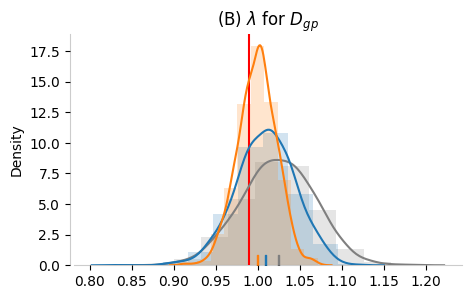

In [7]:
fig = plt.figure(figsize=(5, 3))

ax = fig.add_subplot(1, 1, 1)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.spines['left'].set_position(('outward', 3)); ax.spines['left'].set_alpha(0.2); ax.spines['bottom'].set_alpha(0.2)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.title('(B) $\lambda$ for $D_{gp}$')
plt.hist(np.array(list(growth_rate_glm_sep.values())).real, alpha=0.2, density=True, color='C7')
plt.hist(np.array(list(growth_rate_gp_sep.values())).real, alpha=0.2, density=True, color='C0')
plt.hist(np.array(list(growth_rate_gpabc_sep.values())).real, alpha=0.2, density=True, color='C1')
# plt.axvline(np.mean(np.array(list(growth_rate_glm_sep.values())).real), color='C7')
# plt.axvline(np.mean(np.array(list(growth_rate_gp_sep.values())).real), color='C0')
# plt.axvline(np.mean(np.array(list(growth_rate_gpabc_sep.values())).real+0.001), color='C1')
plt.axvline(true_lambda_gp.real, color='red', label='True')
sns.kdeplot(np.array(list(growth_rate_glm_sep.values())).real, color='C7', label='GLM', bw_adjust=1.3)
sns.kdeplot(np.array(list(growth_rate_gp_sep.values())).real, color='C0', label='GP', bw_adjust=1.3)
sns.kdeplot(np.array(list(growth_rate_gpabc_sep.values())).real, color='C1', label='ABC_GP', bw_adjust=1.3)
plt.plot(np.mean(np.array(list(growth_rate_glm_sep.values())).real), 0.3, marker='$|$',color='C7', markersize=10)
plt.plot(np.mean(np.array(list(growth_rate_gp_sep.values())).real), 0.3, marker='$|$',color='C0', markersize=10)
plt.plot(np.mean(np.array(list(growth_rate_gpabc_sep.values())).real), 0.3, marker='$|$',color='C1', markersize=10)
# plt.savefig('plot11112.pdf')  

# plt.legend()


In [8]:
kl_stable_glm_sep = []
for i in range(5000):
    kl_stable_glm_sep.append(np.sum(np.log(stable_glm_sep[i]/true_stable_gp) * stable_glm_sep[i]))

kl_stable_gp_sep = []
for i in range(5000):
    kl_stable_gp_sep.append(np.sum(np.log(stable_gp_sep[i]/true_stable_gp) * stable_gp_sep[i]))

kl_stable_gpabc_sep = []
for i in range(5000):
    kl_stable_gpabc_sep.append(np.sum(np.log(stable_gpabc_sep[i]/true_stable_gp) * stable_gpabc_sep[i]))

In [9]:
kl_stable_rep_glm_sep = []
for i in range(5000):
    kl_stable_rep_glm_sep.append(np.sum(np.log(stable_rep_glm_sep[i]/true_stable_rep_gp) * stable_rep_glm_sep[i]))
kl_stable_rep_gp_sep = []
for i in range(5000):
    kl_stable_rep_gp_sep.append(np.sum(np.log(stable_rep_gp_sep[i]/true_stable_rep_gp) * stable_rep_gp_sep[i]))

kl_stable_rep_gpabc_sep = []
for i in range(5000):
    kl_stable_rep_gpabc_sep.append(np.sum(np.log(stable_rep_gpabc_sep[i]/true_stable_rep_gp) * stable_rep_gpabc_sep[i]))

In [10]:
def cosine_similarity(vector1, vector2):
    dot_product = np.dot(vector1, vector2)
    norm_vector1 = np.linalg.norm(vector1)
    norm_vector2 = np.linalg.norm(vector2)
    return dot_product / (norm_vector1 * norm_vector2)
# def euclidean_distance(vector1, vector2):
    # return np.sqrt(np.sum((vector1 - vector2)**2))
# Example usage
denom = np.linalg.eig(true_p_gp.T+true_f_gp.T)[1][:,0].real[0]
cos_repro_glm_sep = []
for i in range(5000):
    cos_repro_glm_sep.append(cosine_similarity(np.abs(repro_glm_sep[i])/denom, true_repro_gp))
cos_repro_gp_sep = []
for i in range(5000):
    cos_repro_gp_sep.append(cosine_similarity(np.abs(repro_gp_sep[i])/denom, true_repro_gp))
cos_repro_gpabc_sep = []
for i in range(5000):
    cos_repro_gpabc_sep.append(cosine_similarity(np.abs(repro_gpabc_sep[i])/denom, true_repro_gp))
cos_repro_glm_nonsep = []



In [11]:
print("MSE for 'sep':")
print(f"GLM:{np.mean((np.array(list(growth_rate_glm_sep.values())).real - true_lambda_gp.real)**2)}")
print(f"GP:{np.mean((np.array(list(growth_rate_gp_sep.values())).real - true_lambda_gp.real)**2)}")
print(f"GP_abc:{np.mean((np.array(list(growth_rate_gpabc_sep.values())).real - true_lambda_gp.real)**2)}")


print("Bias for 'sep':")
print(f"GLM:{np.mean((np.array(list(growth_rate_glm_sep.values())).real - true_lambda_gp.real))}")
print(f"GP:{np.mean((np.array(list(growth_rate_gp_sep.values())).real - true_lambda_gp.real))}")
print(f"GP_abc:{np.mean((np.array(list(growth_rate_gpabc_sep.values())).real - true_lambda_gp.real))}")

print("(mean) KL in stable distribution for 'sep':")
print(f"GLM:{np.round(np.mean(kl_stable_glm_sep), 4)}")
print(f"GP:{np.round(np.mean(kl_stable_gp_sep), 4)}")
print(f"GP_abc:{np.round(np.mean(kl_stable_gpabc_sep), 4)}")

print("(mean) KL in stable rep for 'sep':")
print(f"GLM:{np.round(np.mean(kl_stable_rep_glm_sep), 4)}")
print(f"GP:{np.round(np.mean(kl_stable_rep_gp_sep), 4)}")
print(f"GP_abc:{np.round(np.mean(kl_stable_rep_gpabc_sep), 4)}")

print("(mean) cos in reproductive values for 'sep':")
print(f"GLM:{np.round(np.mean(cos_repro_glm_sep), 4)}")
print(f"GP:{np.round(np.mean(cos_repro_gp_sep), 4)}")
print(f"GP_abc:{np.round(np.mean(cos_repro_gpabc_sep), 4)}")

MSE for 'sep':
GLM:0.003129325831171524
GP:0.0016262029291649667
GP_abc:0.000622520244314988
Bias for 'sep':
GLM:0.03450548714275285
GP:0.019511927384496693
GP_abc:0.009554511023533682
(mean) KL in stable distribution for 'sep':
GLM:0.0097
GP:0.0037
GP_abc:0.0018
(mean) KL in stable rep for 'sep':
GLM:0.0249
GP:0.014
GP_abc:0.0122
(mean) cos in reproductive values for 'sep':
GLM:0.9764
GP:0.9947
GP_abc:0.9943


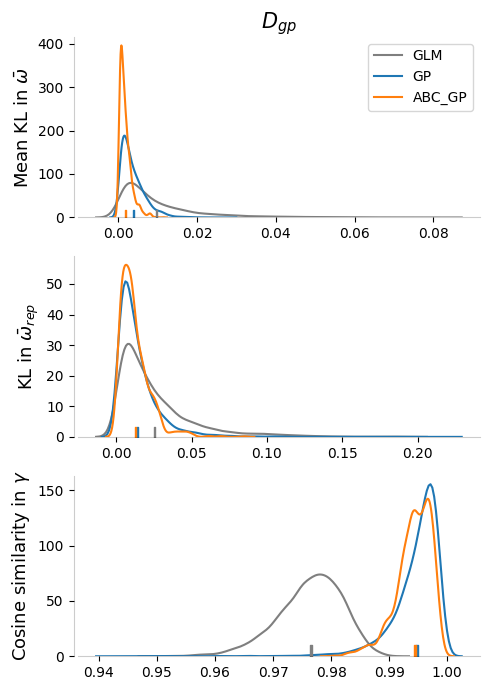

In [12]:
# Create figure and subplots
fig = plt.figure(figsize=(5, 7))

# Colors for each dataset
colors = ['C0', 'C1', 'C2']

# Violin plot for the first set of data (separated)
ax1 = fig.add_subplot(3, 1, 1)
plt.ylabel(r"Mean KL in $\bar{\omega}$",fontsize=13)
# ax1.xaxis.set_major_locator(MaxNLocator(integer=True))
ax1.spines['left'].set_position(('outward', 3)); ax1.spines['left'].set_alpha(0.2); ax1.spines['bottom'].set_alpha(0.2)
ax1.spines['top'].set_visible(False); ax1.spines['right'].set_visible(False)
plt.title('$D_{gp}$',fontsize=15)
sns.kdeplot(kl_stable_glm_sep, color='C7', label='GLM')
sns.kdeplot(kl_stable_gp_sep, color='C0',  label='GP', bw_adjust=1.3)
sns.kdeplot(kl_stable_gpabc_sep, color='C1',  label='ABC_GP', bw_adjust=1.3)
plt.plot(np.mean(kl_stable_glm_sep), 1, marker='$|$', color='C7', markersize=10)
plt.plot(np.mean(kl_stable_gp_sep), 1,  marker='$|$', color='C0', markersize=10)
plt.plot(np.mean(kl_stable_gpabc_sep), 1, marker='$|$', color='C1', markersize=10)

plt.xlabel('')
plt.legend()

# Violin plot for the first set of data (separated)
ax1 = fig.add_subplot(3, 1, 2)
plt.ylabel(r"KL in $\bar{\omega}_{rep}$",fontsize=13)
# ax1.xaxis.set_major_locator(MaxNLocator(integer=True))
ax1.spines['left'].set_position(('outward', 3)); ax1.spines['left'].set_alpha(0.2); ax1.spines['bottom'].set_alpha(0.2)
ax1.spines['top'].set_visible(False); ax1.spines['right'].set_visible(False)


sns.kdeplot(kl_stable_rep_glm_sep, color='C7')
sns.kdeplot(kl_stable_rep_gp_sep, color='C0', bw_adjust=1.3)
sns.kdeplot(kl_stable_rep_gpabc_sep, color='C1', bw_adjust=1.3)
plt.plot(np.mean(kl_stable_rep_glm_sep), 1, marker='$|$', color='C7', markersize=10)
plt.plot(np.mean(kl_stable_rep_gp_sep), 1,  marker='$|$', color='C0', markersize=10)
plt.plot(np.mean(kl_stable_rep_gpabc_sep), 1, marker='$|$', color='C1', markersize=10)



# Violin plot for the first set of data (separated)
ax1 = fig.add_subplot(3, 1, 3)
plt.ylabel(r"Cosine similarity in $\gamma$",fontsize=13)
# ax1.xaxis.set_major_locator(MaxNLocator(integer=True))
ax1.spines['left'].set_position(('outward', 3)); ax1.spines['left'].set_alpha(0.2); ax1.spines['bottom'].set_alpha(0.2)
ax1.spines['top'].set_visible(False); ax1.spines['right'].set_visible(False)
sns.kdeplot(cos_repro_glm_sep, color='C7')
sns.kdeplot(cos_repro_gp_sep, color='C0', bw_adjust=1.3)
sns.kdeplot(cos_repro_gpabc_sep, color='C1', bw_adjust=1.3)
plt.plot(np.mean(cos_repro_glm_sep), 1, marker='$|$', color='C7', markersize=15)
plt.plot(np.mean(cos_repro_gp_sep), 1,  marker='$|$', color='C0', markersize=15)
plt.plot(np.mean(cos_repro_gpabc_sep), 1, marker='$|$', color='C1', markersize=15)


plt.tight_layout()
# plt.savefig('plot22222.pdf')  
plt.show()


In [ ]:
data_style = 'gp'

popu_dataset = globals()[f'{data_style}_mle_true_population']
true_models = globals()[f'{data_style}_mle_true_models']
true_p = globals()[f'true_p_{data_style}']
true_f = globals()[f'true_f_{data_style}']
true_kernel = true_p + true_f

true_kernel_norm = np.linalg.norm(true_kernel)
true_p_norm = np.linalg.norm(true_p)
true_f_norm = np.linalg.norm(true_f)

mcmc_path = os.getcwd() + f"/true_popu/{data_style}_mle_true_population/MCMC"
rates = ['sur', 'grw_f', 'grw_nf', 'fec', 'flow']

df = {
    'sur': XY_sur_compu(popu_dataset),
    'grw_f': XY_grw_f_compu(popu_dataset),
    'grw_nf': XY_grw_nf_compu(popu_dataset),
    'fec': XY_fec_compu(popu_dataset),
    'flow': XY_flow_compu(popu_dataset)
}
recruitment = {name: true_models[name] for name in ['recruit_p', 'alpha', 'beta']}

kernel_error = {'GLM': [], 'GP': [], 'ABC_GP': []}
p_error = {'GLM': [], 'GP': [], 'ABC_GP': []}
f_error = {'GLM': [], 'GP': [], 'ABC_GP': []}

# GP and ABC GP
gp_models = recruitment.copy()
gp_state = {}
gp_samples = {}

for rate in rates:
    data = (df[rate][0], df[rate][1])
    kernel = gpflow.kernels.RBF()

    if rate in ['grw_f', 'grw_nf']:
        model = gpflow.models.GPR(data=data, kernel=kernel)
    else:
        likelihood = gpflow.likelihoods.Poisson() if rate == 'flow' else gpflow.likelihoods.Bernoulli()
        model = gpflow.models.GPMC(data=data, kernel=kernel, likelihood=likelihood)

    name = 'm_flow_poi' if rate == 'flow' else f'm_{rate}'
    gp_models[name] = model
    gp_state[rate] = [p.unconstrained_variable for p in model.trainable_parameters]

    with open(mcmc_path + f"/gp/sep/samples_{rate}.pkl", "rb") as file:
        gp_samples[rate] = pickle.load(file)

abc_iter = {'glm': 6, 'gp': 9}[data_style]
abc_path = os.getcwd() + f"/ABC_details/{data_style}sep"
abc_index = np.load(abc_path + f"/p_index_{abc_iter}.pkl")
abc_weight = np.load(abc_path + f"/weight{abc_iter}.pkl").ravel()
abc_weight = abc_weight / abc_weight.sum()

rng = np.random.RandomState(1234567)
gp_index = rng.randint(0, 5000, size=(5000, len(rates)))

for method, draw_index in [('GP', gp_index), ('ABC_GP', abc_index)]:
    for c_index in draw_index:
        for rate, j in zip(rates, c_index):
            for var, samples in zip(gp_state[rate], gp_samples[rate]):
                var.assign(samples[j])

        c_p, c_f = IPM_listk(mesh_setting, gp_models, 'sep')
        kernel_error[method].append(np.linalg.norm(c_p + c_f - true_kernel) / true_kernel_norm)
        p_error[method].append(np.linalg.norm(c_p - true_p) / true_p_norm)
        f_error[method].append(np.linalg.norm(c_f - true_f) / true_f_norm)

# GLM
glm_models = recruitment.copy()
glm_models['m_sur'] = bmb.Model("sur ~ size", pd.concat(df['sur'], axis=1), family='bernoulli')
glm_models['m_grw_f'] = bmb.Model("sizeNext ~ size", pd.concat(df['grw_f'], axis=1))
glm_models['m_grw_nf'] = bmb.Model("sizeNext ~ size", pd.concat(df['grw_nf'], axis=1))
glm_models['m_fec'] = bmb.Model("fec ~ size", pd.concat(df['fec'], axis=1), family='bernoulli')
glm_models['m_flow_poi'] = bmb.Model("flow ~ size", pd.concat(df['flow'], axis=1), family='poisson')

glm_trace = {}
for rate in rates:
    with open(mcmc_path + f"/glm/sep/trace_{rate}.pkl", "rb") as file:
        glm_trace[f'trace_{rate}'] = pickle.load(file)

with open(os.getcwd() + f"/IPM_matrix/{data_style}_data/sepglm/index.pkl", "rb") as file:
    glm_index = pickle.load(file)

for c_index in glm_index.values():
    c_p, c_f = IPM_listk_glmmcmc(mesh_setting, glm_models, glm_trace, c_index, 'sep')
    kernel_error['GLM'].append(np.linalg.norm(c_p + c_f - true_kernel) / true_kernel_norm)
    p_error['GLM'].append(np.linalg.norm(c_p - true_p) / true_p_norm)
    f_error['GLM'].append(np.linalg.norm(c_f - true_f) / true_f_norm)


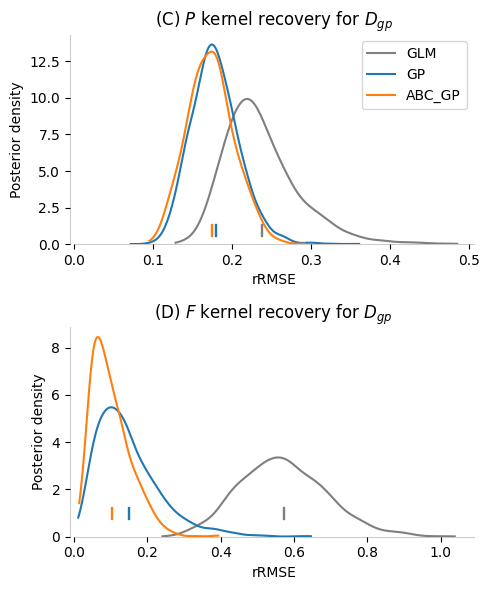

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(5, 6))

for ax, panel, part, error in zip(
        axes, ['C', 'D'], ['P', 'F'], [p_error, f_error]):

    plt.sca(ax)
    ax.spines['left'].set_position(('outward', 3))
    ax.spines['left'].set_alpha(0.2)
    ax.spines['bottom'].set_alpha(0.2)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    sns.kdeplot(x=error['GLM'], color='C7', label='GLM',
                bw_adjust=1.3, cut=0)
    sns.kdeplot(x=error['GP'], color='C0', label='GP',
                bw_adjust=1.3, cut=0)
    sns.kdeplot(x=error['ABC_GP'], weights=abc_weight, color='C1',
                label='ABC_GP', bw_adjust=1.3, cut=0)

    plt.plot(np.mean(error['GLM']), 1, marker='$|$', color='C7', markersize=8)
    plt.plot(np.mean(error['GP']), 1, marker='$|$', color='C0', markersize=8)
    plt.plot(np.average(error['ABC_GP'], weights=abc_weight), 1,
             marker='$|$', color='C1', markersize=8)

    plt.title(rf'({panel}) ${part}$ kernel recovery for $D_{{{data_style}}}$')
    plt.xlabel('rRMSE')
    plt.ylabel('Posterior density')
    plt.xlim(left=0)

axes[0].legend()
plt.tight_layout()
# plt.savefig('plot_kernel2.pdf')
plt.show()